# Automatic separation of doors by color

## Imports

In [2]:
import cv2
import random
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt

## Config

In [3]:
DATA_DIR = Path(r"G:\B1375\DATA\Top")

In [4]:
SUPPORTED_IMAGE_FORMATS = [".jpg", ".jpeg", ".png", ".bmp", ".tiff"]

## Brown vs White doors

### Separación automática de puertas por color
Vamos a analizar un pixel que siempre cae dentro de la puerta. Si la puerta es blanca el píxel tendrá bastante más intensidad que cuando sea marrón, así que podemos establecer un umbral de intensidad y considerar que si una puerta tiene un valor superior a ese umbral en ese píxel específico, entonces esa puerta será blanca. Hacemos un analisis para establecer el valor del umbral:

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:51<00:00,  5.17s/it]


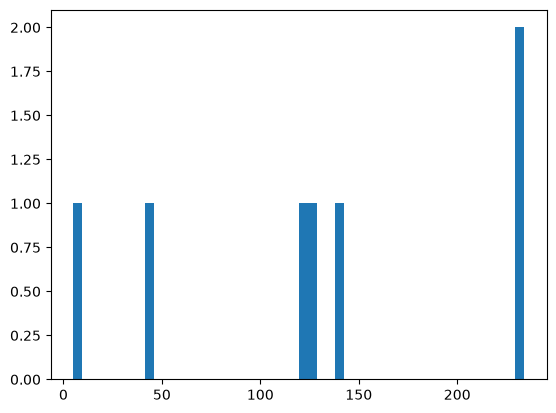

In [5]:
PXL_LOCATION = (3000, 11000)
MAX_IMGS = 10

pxl_values_gray = []
img_paths = []
for file in tqdm((random.sample(list(DATA_DIR.glob("*")), MAX_IMGS))):
    if file.suffix.lower() in SUPPORTED_IMAGE_FORMATS:
        img = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)

        if img is not None and img.shape[0] > PXL_LOCATION[1] and img.shape[1] > PXL_LOCATION[0]:
            pxl_value = img[PXL_LOCATION[1], PXL_LOCATION[0]]
            pxl_values_gray.append(pxl_value)
            img_paths.append(file)

plt.hist(pxl_values_gray, bins=50)
plt.show()

Validamos el valor del umbral:

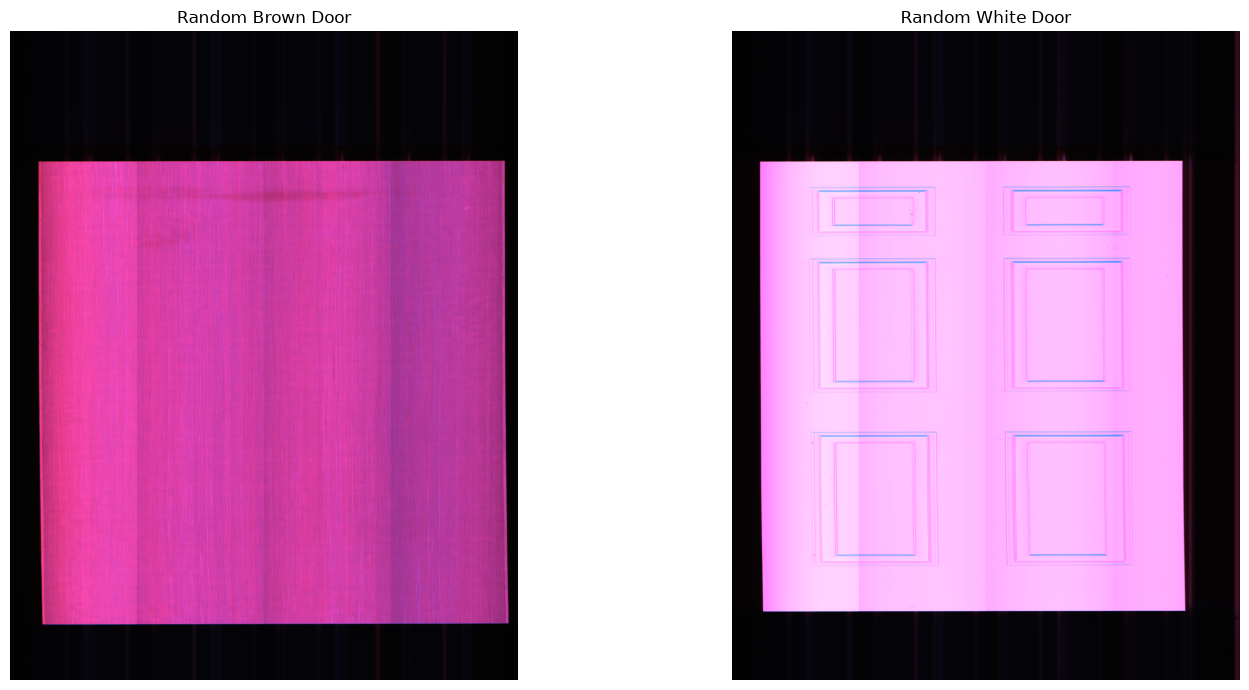

In [9]:
PXL_THRESH = 190

brown_doors = [img_paths[i] for i, pxl_value in enumerate(pxl_values_gray) if pxl_value < PXL_THRESH]
white_doors = [img_paths[i] for i, pxl_value in enumerate(pxl_values_gray) if pxl_value >= PXL_THRESH]

def load_resized_image(img_path, target_size=(2350, 3000)):
    img = cv2.imread(str(img_path), cv2.IMREAD_REDUCED_COLOR_2)
    if img is None:
        raise ValueError(f"No se pudo leer: {img_path}")
    img = cv2.resize(img, target_size, interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


brown_path = random.choice(brown_doors)
white_path = random.choice(white_doors)

resized_brown = load_resized_image(brown_path)
resized_white = load_resized_image(white_path)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(resized_brown)
axes[0].set_title("Random Brown Door")
axes[0].axis("off")

axes[1].imshow(resized_white)
axes[1].set_title("Random White Door")
axes[1].axis("off")

plt.tight_layout()
plt.show()